,epoch,train_loss,validation_loss,validation_mean_iou
0,1,5.185095,3.177992,0.022019


,channel,material,iou
0,0,Animal skin,NaN
1,1,Bone/teeth/horn,NaN
2,2,Brickwork,NaN
3,3,Cardboard,NaN
4,4,Carpet/rug,0.000000
5,5,Ceiling tile,NaN
6,6,Ceramic,NaN
7,7,Chalkboard/blackboard,NaN
8,8,Clutter,NaN
9,9,Concrete,NaN


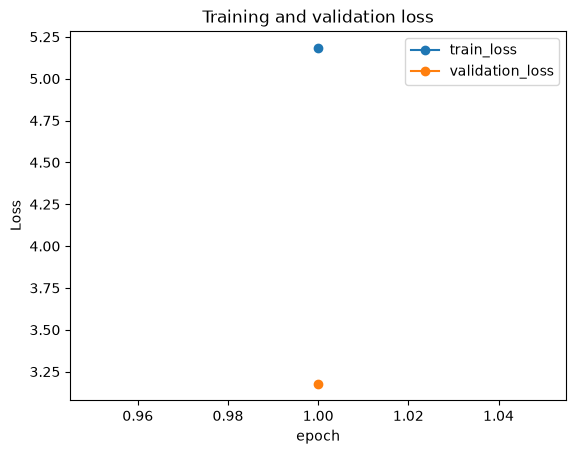

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "training/train_dms.py").is_file()
)

results = root / "training/runs/dms-pilot"
history = pd.read_csv(results / "history.csv")
scores = pd.read_csv(results / "validation_per_class.csv")

display(history)
display(scores)

history.plot(
    x="epoch",
    y=["train_loss", "validation_loss"],
    marker="o",
    title="Training and validation loss"
)
plt.ylabel("Loss")
plt.show()

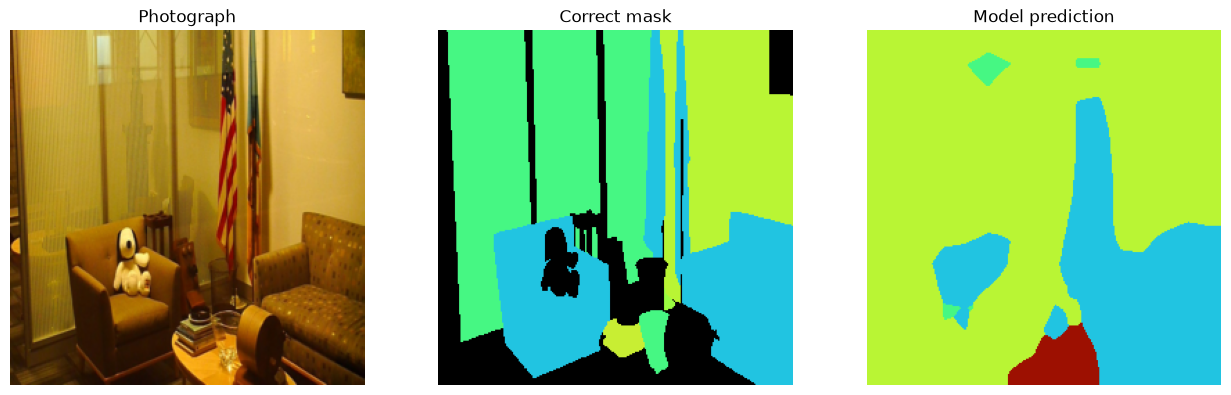

Predicted materials: Fabric/cloth, Glass, Paint/plaster/enamel, Wood


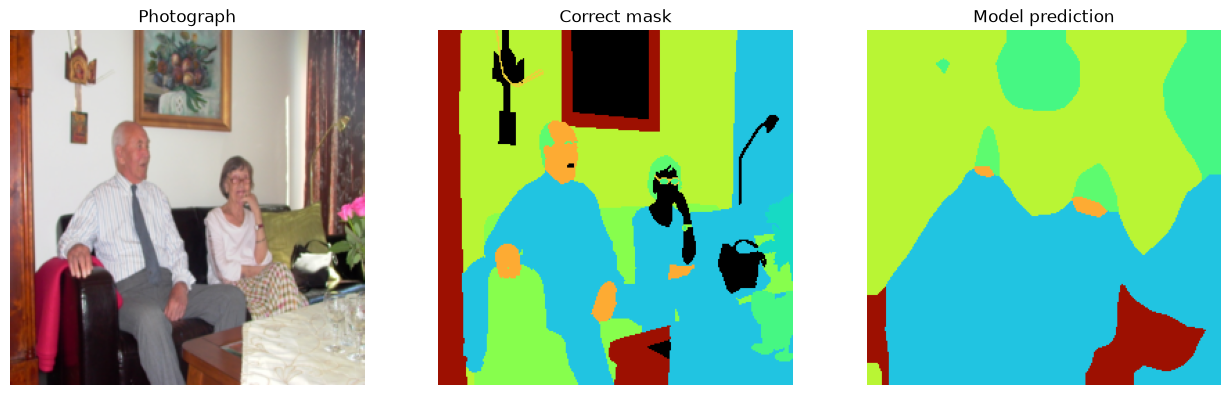

Predicted materials: Fabric/cloth, Glass, Hair, Paint/plaster/enamel, Skin/lips, Wood


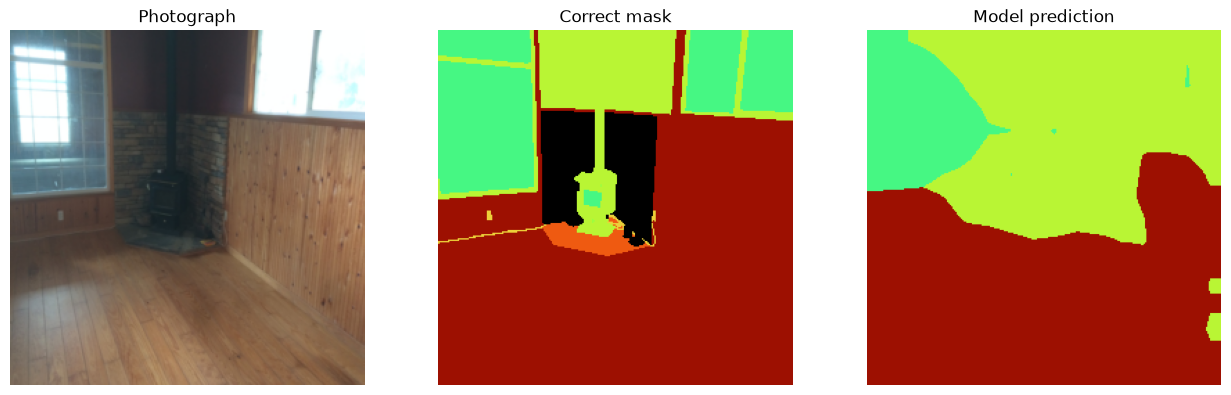

Predicted materials: Glass, Paint/plaster/enamel, Wood


In [5]:
from pathlib import Path
import csv
import importlib.util

import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large

# Find the project folder
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "training/train_dms.py").is_file()
)
data = root / "datasets/dms/local_data/DMS_v1"

# Use the same image preparation as the training script
spec = importlib.util.spec_from_file_location(
    "dms_training", root / "training/train_dms.py"
)
training = importlib.util.module_from_spec(spec)
spec.loader.exec_module(training)

# Load the checkpoint you created
saved = torch.load(
    root / "training/runs/dms-expanded/best.pt",
    map_location="cpu",
    weights_only=True
)

model = deeplabv3_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=46,
    aux_loss=True
)
model.load_state_dict(saved["state_dict"])
model.eval()

# Select accepted validation photographs
with (data / "pilot_manifest.csv").open(
    newline="", encoding="utf-8"
) as f:
    rows = [
        row for row in csv.DictReader(f)
        if row["status"] == "accepted"
        and row["split"] == "validation"
    ]

assert rows, "No accepted validation images were found."

dataset = training.Pairs(
    data, rows, saved["classes"], saved["size"]
)

# Give each model class a consistent display colour
colours = plt.get_cmap("turbo")(np.linspace(0, 1, 46))[:, :3]

for index in range(min(3, len(dataset))):
    image, target = dataset[index]

    with torch.inference_mode():
        prediction = model(image.unsqueeze(0))["out"].argmax(1)[0].numpy()

    # Undo normalisation for displaying the photograph
    photo = image.numpy().transpose(1, 2, 0)
    photo = photo * np.array([0.229, 0.224, 0.225])
    photo = np.clip(
        photo + np.array([0.485, 0.456, 0.406]), 0, 1
    )

    target = target.numpy()
    correct = np.zeros((*target.shape, 3))
    valid = target != 255
    correct[valid] = colours[target[valid]]

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(photo)
    axes[1].imshow(correct)
    axes[2].imshow(colours[prediction])

    for ax, title in zip(
        axes, ["Photograph", "Correct mask", "Model prediction"]
    ):
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    names = {
        int(c["model_channel"]): c["material_name"]
        for c in saved["classes"]
    }
    print(
        "Predicted materials:",
        ", ".join(names[int(c)] for c in np.unique(prediction))
    )

,experiment,best_epoch,validation_IoU_percent
0,dms-pilot,1,2.201909
1,dms-10epochs,9,4.372700


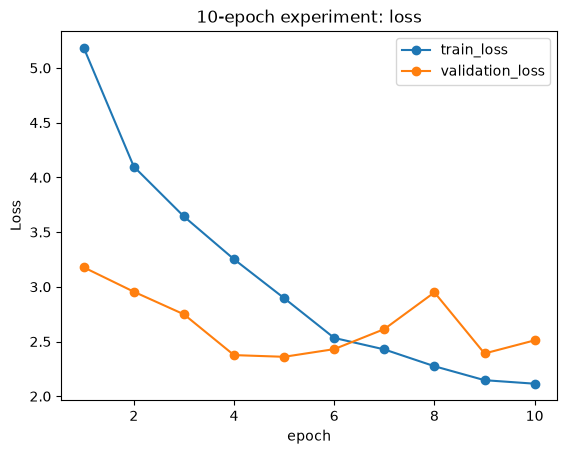

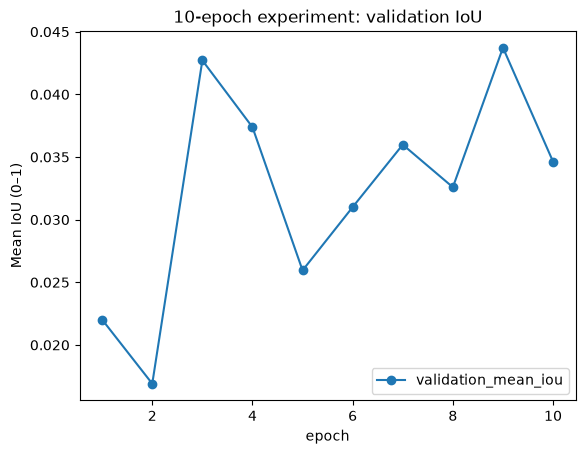

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "training/train_dms.py").is_file()
)

results = []

for run in ["dms-pilot", "dms-10epochs"]:
    history = pd.read_csv(
        root / "training/runs" / run / "history.csv"
    )

    best = history.loc[history["validation_mean_iou"].idxmax()]
    results.append({
        "experiment": run,
        "best_epoch": int(best["epoch"]),
        "validation_IoU_percent": best["validation_mean_iou"] * 100
    })

display(pd.DataFrame(results))

history.plot(
    x="epoch",
    y=["train_loss", "validation_loss"],
    marker="o",
    title="10-epoch experiment: loss"
)
plt.ylabel("Loss")
plt.show()

history.plot(
    x="epoch",
    y="validation_mean_iou",
    marker="o",
    title="10-epoch experiment: validation IoU"
)
plt.ylabel("Mean IoU (0–1)")
plt.show()

In [4]:
from pathlib import Path
import pandas as pd

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "datasets/dms").is_dir()
)

manifest = pd.read_csv(
    root / "datasets/dms/local_data/DMS_v1/pilot_manifest.csv"
)

display(pd.crosstab(manifest["split"], manifest["status"]))

display(
    manifest.loc[manifest["status"] == "excluded", "detail"]
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="count")
)

status,accepted,excluded
split,,
test,10,15
train,81,119
validation,21,29


,reason,count
0,Image ID is not available in the CVDF mirror; ...,163


,epoch,train_loss,validation_loss,validation_mean_iou
0,1,4.021130,2.636124,0.024781
1,2,3.128157,2.386651,0.061938
2,3,2.706322,2.430858,0.059644
3,4,2.372980,2.375867,0.059222
4,5,2.137542,2.130307,0.076521
5,6,1.944378,2.377362,0.088515
6,7,1.879978,2.335392,0.082642
7,8,1.817966,2.483882,0.075641
8,9,1.748373,2.934667,0.077083
9,10,1.672203,2.571648,0.083030


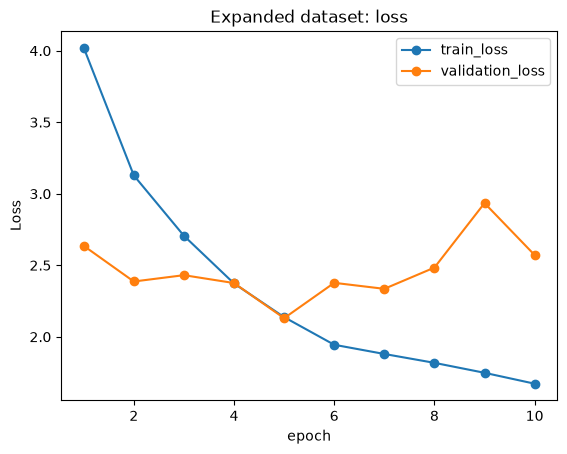

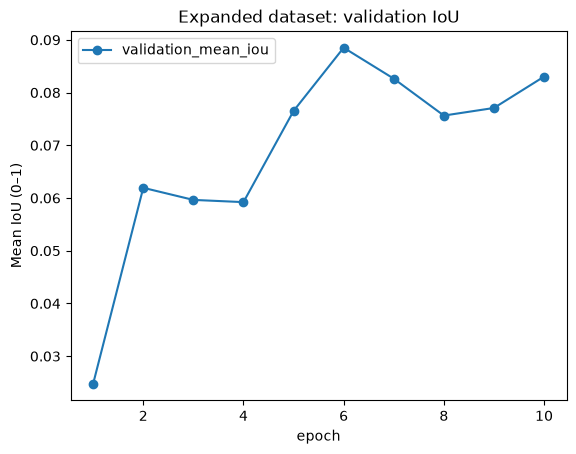

In [6]:
history_path = root / "training/runs/dms-expanded/history.csv"

if not history_path.exists():
    print("Expanded training results not found. Finish training first.")
else:
    history = pd.read_csv(history_path)
    display(history)

    history.plot(
        x="epoch",
        y=["train_loss", "validation_loss"],
        marker="o",
        title="Expanded dataset: loss"
    )
    plt.ylabel("Loss")
    plt.show()

    history.plot(
        x="epoch",
        y="validation_mean_iou",
        marker="o",
        title="Expanded dataset: validation IoU"
    )
    plt.ylabel("Mean IoU (0–1)")
    plt.show()

In [7]:
history = pd.read_csv(
    root / "training/runs/dms-expanded/history.csv"
)

best = history.loc[history["validation_mean_iou"].idxmax()]

print("Best epoch:", int(best["epoch"]))
print(f"Best validation mean IoU: {best['validation_mean_iou']:.2%}")

Best epoch: 6
Best validation mean IoU: 8.85%


Loaded epoch: 6
Saved validation IoU: 8.85%


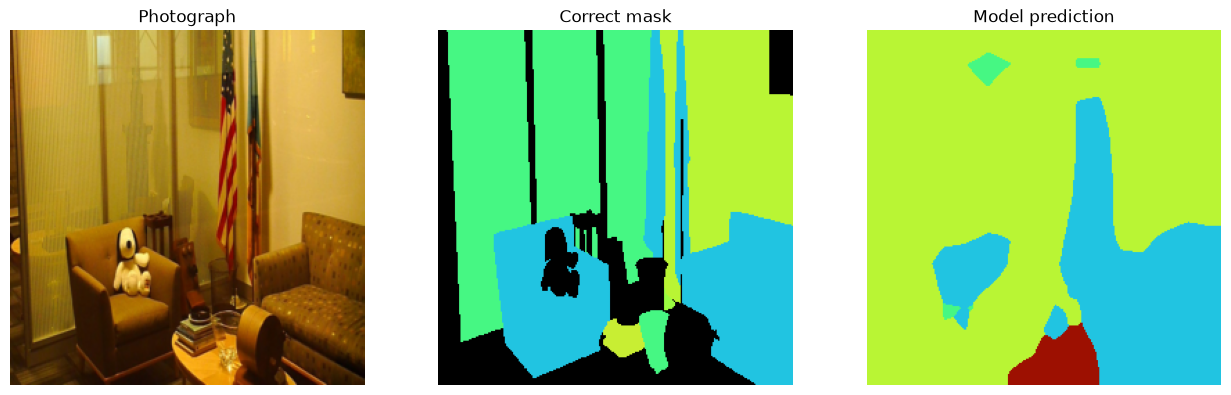

Predicted materials: Fabric/cloth, Glass, Paint/plaster/enamel, Wood


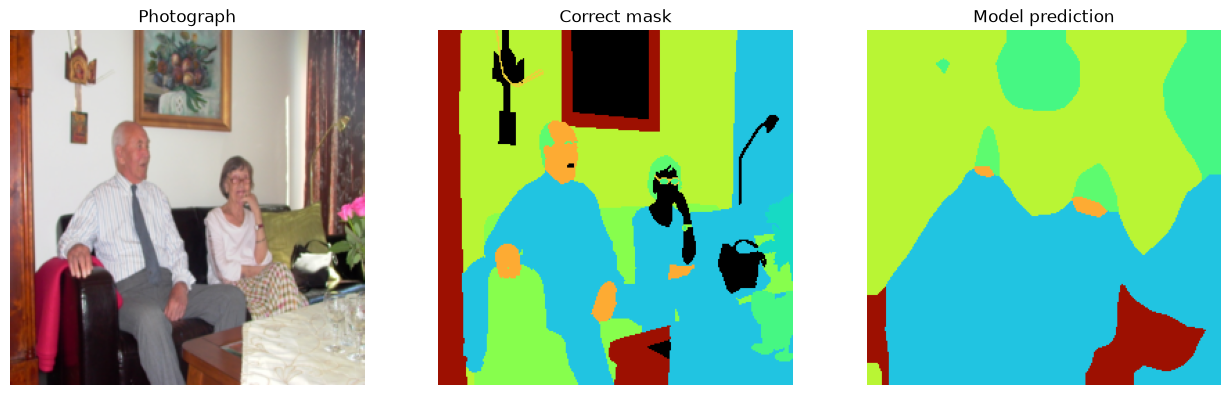

Predicted materials: Fabric/cloth, Glass, Hair, Paint/plaster/enamel, Skin/lips, Wood


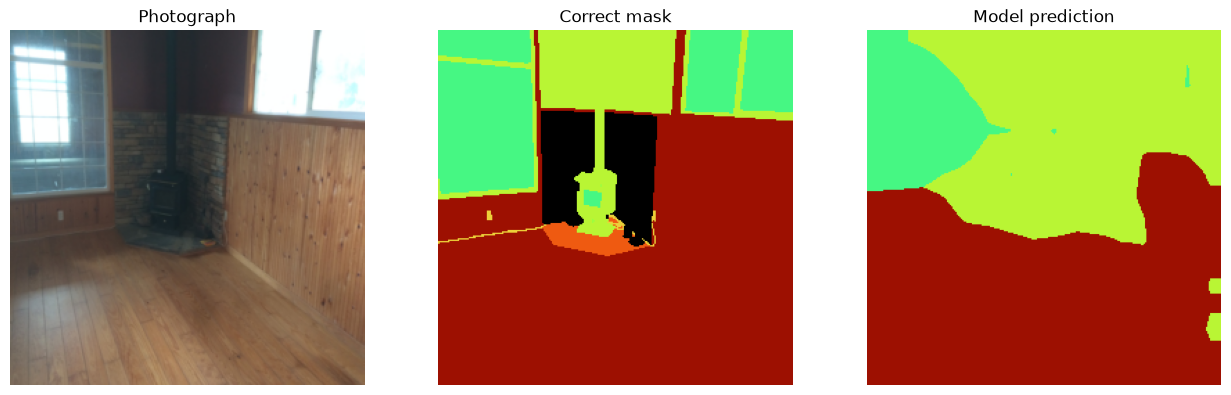

Predicted materials: Glass, Paint/plaster/enamel, Wood


In [8]:
from pathlib import Path
import csv
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large

# Locate your project
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "training/train_dms.py").is_file()
)

data = root / "datasets/dms/local_data/DMS_v1"
checkpoint = root / "training/runs/dms-expanded/best.pt"

if not checkpoint.exists():
    raise FileNotFoundError(f"Model not found: {checkpoint}")

# Load the same preparation code used during training
spec = importlib.util.spec_from_file_location(
    "dms_training", root / "training/train_dms.py"
)
training = importlib.util.module_from_spec(spec)
spec.loader.exec_module(training)

# Load your saved model
saved = torch.load(
    checkpoint, map_location="cpu", weights_only=True
)

model = deeplabv3_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=46,
    aux_loss=True
)
model.load_state_dict(saved["state_dict"])
model.eval()

print("Loaded epoch:", saved["epoch"])
print(f"Saved validation IoU: {saved['validation_mean_iou']:.2%}")

# Select validation images
with (data / "pilot_manifest.csv").open(
    newline="", encoding="utf-8"
) as f:
    rows = [
        row for row in csv.DictReader(f)
        if row["status"] == "accepted"
        and row["split"] == "validation"
    ]

if not rows:
    raise ValueError("No accepted validation images found.")

dataset = training.Pairs(
    data, rows, saved["classes"], saved["size"]
)

colours = plt.get_cmap("turbo")(np.linspace(0, 1, 46))[:, :3]
names = {
    int(c["model_channel"]): c["material_name"]
    for c in saved["classes"]
}

for index in range(min(3, len(dataset))):
    image, target = dataset[index]

    with torch.inference_mode():
        prediction = (
            model(image.unsqueeze(0))["out"]
            .argmax(1)[0].numpy()
        )

    photo = image.numpy().transpose(1, 2, 0)
    photo = photo * np.array([0.229, 0.224, 0.225])
    photo = np.clip(
        photo + np.array([0.485, 0.456, 0.406]), 0, 1
    )

    target = target.numpy()
    correct = np.zeros((*target.shape, 3))
    valid = target != 255
    correct[valid] = colours[target[valid]]

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    for ax, picture, title in zip(
        axes,
        [photo, correct, colours[prediction]],
        ["Photograph", "Correct mask", "Model prediction"]
    ):
        ax.imshow(picture)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(
        "Predicted materials:",
        ", ".join(names[int(c)] for c in np.unique(prediction))
    )

In [9]:
import pandas as pd
import numpy as np
from PIL import Image

data = root / "datasets/dms/local_data/DMS_v1"
manifest = pd.read_csv(data / "pilot_manifest.csv")
taxonomy = pd.read_csv(root / "datasets/dms/taxonomy.csv")

counts = {}

# Count photographs containing each material.
# Leave test images untouched.
for split in ["train", "validation"]:
    count = np.zeros(256, dtype=int)

    rows = manifest[
        manifest["status"].eq("accepted")
        & manifest["split"].eq(split)
    ]

    for relative_path in rows["label_path"]:
        with Image.open(data / relative_path) as mask:
            labels = np.unique(np.asarray(mask))

        count[labels.astype(int)] += 1

    counts[split] = count

coverage = taxonomy[["label_id", "name"]].copy()

for split, count in counts.items():
    coverage[split + "_images"] = coverage["label_id"].map(
        lambda label: int(count[int(label)])
    )

targets = [
    "Wood", "Brickwork", "Fabric/cloth", "Glass",
    "Mirror", "Paint/plaster/enamel", "Metal",
    "Concrete", "Tile"
]

display(coverage[coverage["name"].isin(targets)])

,label_id,name,train_images,validation_images
3,3,Brickwork,3,1
10,10,Concrete,2,1
13,13,Fabric/cloth,63,17
20,20,Glass,60,13
26,26,Metal,53,15
27,27,Mirror,5,0
29,29,Paint/plaster/enamel,74,21
46,46,Tile,22,5
52,52,Wood,38,9
